In [5]:
import matplotlib.pyplot as plt
import pandas as pd

In [6]:
import analysis_utils as au

In [9]:
stardew_df = au.load_mod_data_per_game("stardewvalley")
stardew_df = au.preprocess_mod_data(stardew_df)

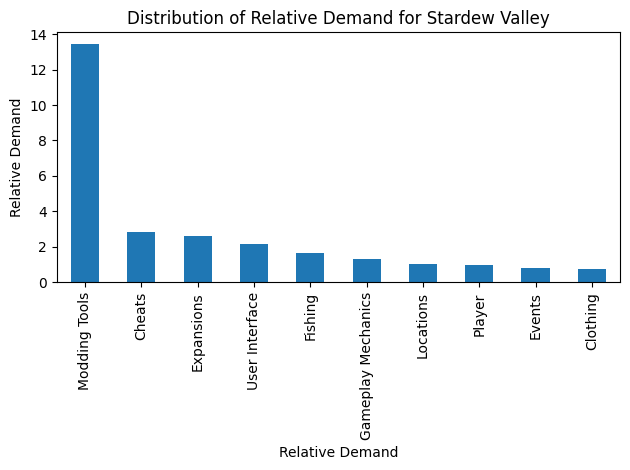

In [10]:
stardew_relative_demand = au.get_relative_demand(stardew_df, game_name="stardewvalley", category_column="modCategory")
au.plot_value_distribution(stardew_relative_demand, category_values=stardew_relative_demand, category_column="Relative Demand", metric="Relative Demand", game_name="Stardew Valley")

In [11]:
skyrim_df = au.load_mod_data_per_game("skyrim")
skyrim_df = au.preprocess_mod_data(skyrim_df)

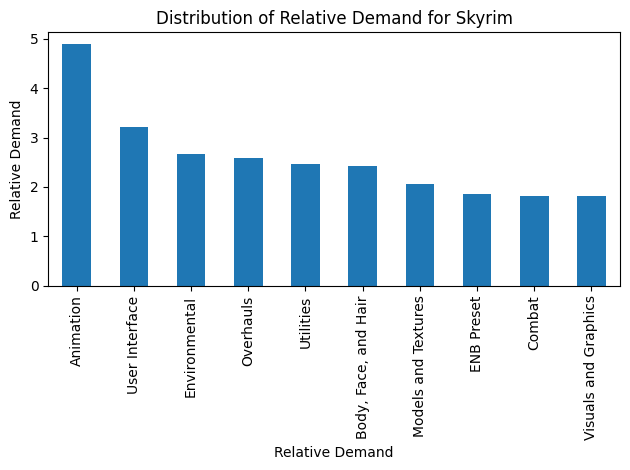

In [13]:
skyrim_relative_demand = au.get_relative_demand(skyrim_df, game_name="skyrim", category_column="modCategory")
au.plot_value_distribution(skyrim_relative_demand, category_values=skyrim_relative_demand, category_column="Relative Demand", metric="Relative Demand", game_name="Skyrim")

In [14]:
cyberpunk_df = au.load_mod_data_per_game("cyberpunk2077")
cyberpunk_df = au.preprocess_mod_data(cyberpunk_df)

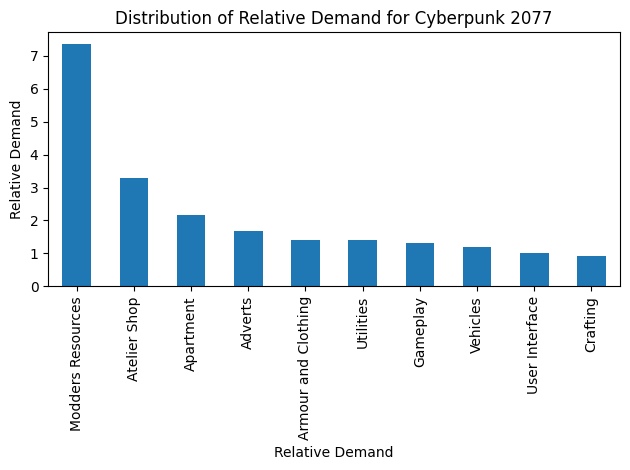

In [15]:
cyberpunk_relative_demand = au.get_relative_demand(cyberpunk_df, game_name="cyberpunk2077", category_column="modCategory")
au.plot_value_distribution(cyberpunk_relative_demand, category_values=cyberpunk_relative_demand, category_column="Relative Demand", metric="Relative Demand", game_name="Cyberpunk 2077")

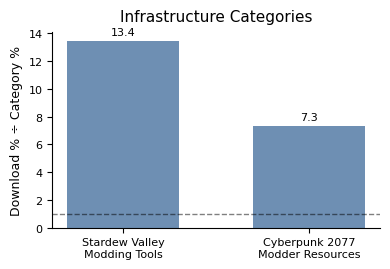

In [16]:
# values taken from your already-computed relative-demand series
infra = {
    "Stardew Valley\nModding Tools": stardew_relative_demand["Modding Tools"],
    "Cyberpunk 2077\nModder Resources": cyberpunk_relative_demand["Modders Resources"]
}

infra_series = pd.Series(infra)

fig, ax = plt.subplots(figsize=(4, 2.8))

bars = ax.bar(
    infra_series.index,
    infra_series.values,
    color="#6E8FB3",
    width=0.6
)

ax.axhline(1, color="black", linestyle="--", linewidth=1, alpha=0.5)

ax.set_ylabel("Download % ÷ Category %", fontsize=9)
ax.set_title("Infrastructure Categories", fontsize=11, pad=8)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="x", labelsize=8)
ax.tick_params(axis="y", labelsize=8)

# add values on bars
for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        h + 0.3,
        f"{h:.1f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [17]:
stardew_relative_demand = stardew_relative_demand.drop(
    ["Modding Tools"], errors="ignore"
)

cyberpunk_relative_demand = cyberpunk_relative_demand.drop(
    ["Modders Resources"], errors="ignore"
)

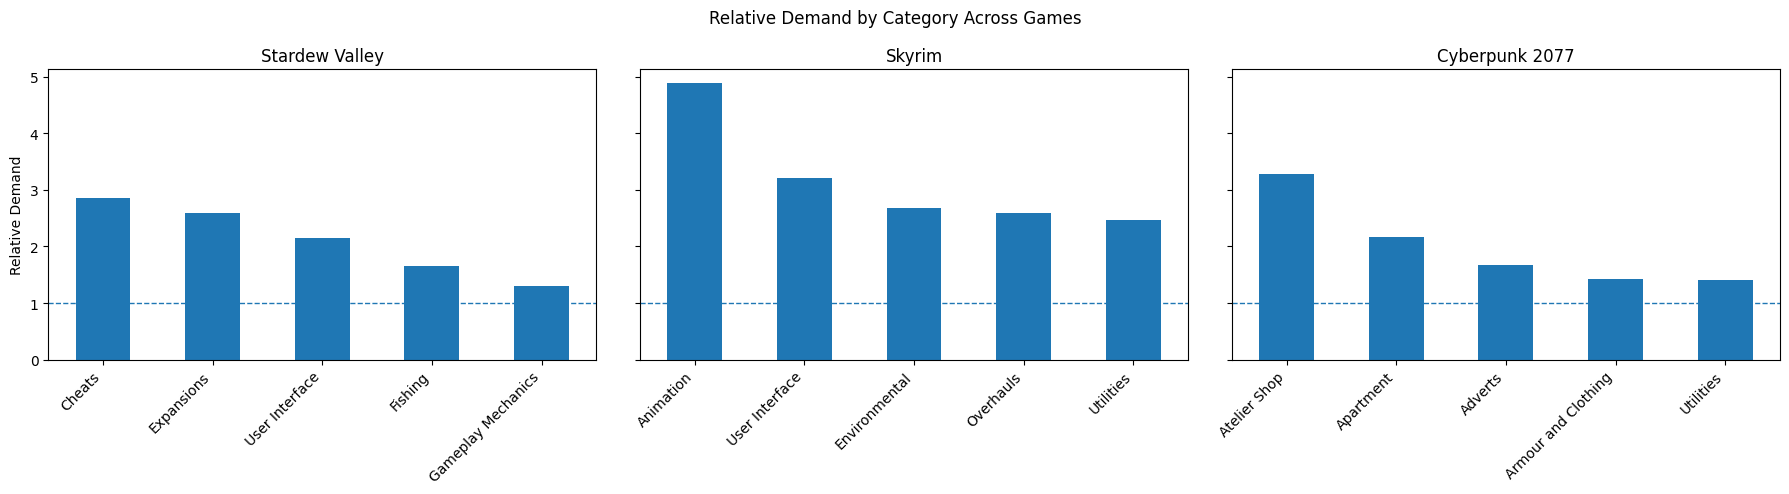

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Stardew
stardew_relative_demand.head(5).plot(kind="bar", ax=axes[0])
axes[0].set_title("Stardew Valley")
axes[0].set_ylabel("Relative Demand")
axes[0].axhline(1, linestyle="--", linewidth=1)

# Skyrim
skyrim_relative_demand.head(5).plot(kind="bar", ax=axes[1])
axes[1].set_title("Skyrim")
axes[1].axhline(1, linestyle="--", linewidth=1)

# Cyberpunk
cyberpunk_relative_demand.head(5).plot(kind="bar", ax=axes[2])
axes[2].set_title("Cyberpunk 2077")
axes[2].axhline(1, linestyle="--", linewidth=1)

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha("right")

plt.suptitle("Relative Demand by Category Across Games")
plt.tight_layout()
plt.show()

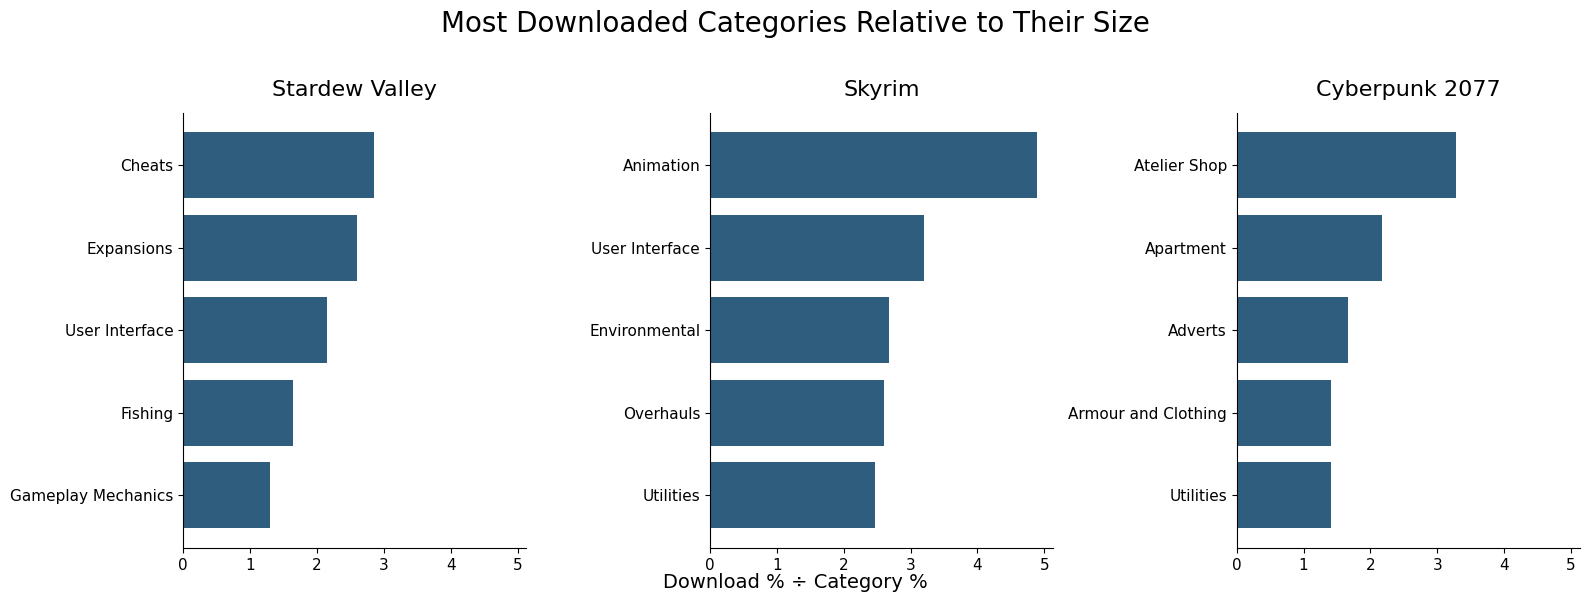

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True)

plots = [
    ("Stardew Valley", stardew_relative_demand.head(5)),
    ("Skyrim", skyrim_relative_demand.head(5)),
    ("Cyberpunk 2077", cyberpunk_relative_demand.head(5)),
]

for ax, (title, data) in zip(axes, plots):
    data = data.sort_values()

    ax.barh(data.index, data.values)

    ax.set_title(title, fontsize=16, pad=12)
    ax.tick_params(axis="y", labelsize=11)
    ax.tick_params(axis="x", labelsize=11)

    # clean up
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.barh(data.index, data.values, color="#2F5D7E")


fig.supxlabel(
    "Download % ÷ Category %",
    fontsize=14,
    y=0.05
)
plt.suptitle("Most Downloaded Categories Relative to Their Size", fontsize=20, y=1.02)
plt.tight_layout()
plt.show()